<a href="https://colab.research.google.com/github/CristianAquino22/Midterm-LLM-Classifier/blob/main/LLM_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q datasets
from huggingface_hub import login
from google.colab import userdata
login(token=userdata.get("token"))

from datasets import load_dataset
import pandas as pd

ds = load_dataset("lmsys/chatbot_arena_conversations", split="train")
df = ds.to_pandas()

print(df.shape)
print(df.columns.tolist())
print(pd.concat([df["model_a"], df["model_b"]]).value_counts())


README.md:   0%|          | 0.00/7.00k [00:00<?, ?B/s]

data/train-00000-of-00001-cced8514c7ed78(…): reconstructing file:   0%|          |  0.00B / 41.6MB            

data/train-00000-of-00001-cced8514c7ed78(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/33000 [00:00<?, ? examples/s]

(33000, 13)
['question_id', 'model_a', 'model_b', 'winner', 'judge', 'conversation_a', 'conversation_b', 'turn', 'anony', 'language', 'tstamp', 'openai_moderation', 'toxic_chat_tag']
vicuna-13b                 5931
koala-13b                  5573
oasst-pythia-12b           4890
gpt-3.5-turbo              4654
alpaca-13b                 4453
gpt-4                      4217
claude-v1                  3927
RWKV-4-Raven-14B           3682
chatglm-6b                 3322
fastchat-t5-3b             3210
palm-2                     2955
vicuna-7b                  2869
mpt-7b-chat                2854
stablelm-tuned-alpha-7b    2795
dolly-v2-12b               2786
claude-instant-v1          2626
llama-13b                  2009
wizardlm-13b               1116
gpt4all-13b-snoozy         1097
guanaco-33b                1034
Name: count, dtype: int64


In [3]:
from sklearn.model_selection import GroupShuffleSplit

family_map = {
    "gpt-3.5-turbo": "GPT", "gpt-4": "GPT",
    "claude-v1": "Claude", "claude-instant-v1": "Claude",
    "llama-13b": "Llama",
}

#clean data
clean = df[(df["language"] == "English") & (df["turn"] == 1)]
clean = clean[~clean["openai_moderation"].apply(lambda m: m["flagged"])] #removes comments flagged as harmful

#Reshape into LLM_name, LLM_Input, LLM_output rows
rows = []
for _, r in clean.iterrows():
    for side in ["a", "b"]:
        model = r[f"model_{side}"]
        if model in family_map:
            conv = r[f"conversation_{side}"]
            rows.append({
                "LLM_name": family_map[model],
                "model": model,
                "LLM_Input": conv[0]["content"],
                "LLM_output": conv[1]["content"],
            })
data = pd.DataFrame(rows)
data = data[data["LLM_output"].str.strip().str.len() > 0]
data = data.drop_duplicates(subset=["LLM_Input", "LLM_output"])
print("After cleaning:\n", data["LLM_name"].value_counts(), "\n")

#sample every family down to the smallest one
n = data["LLM_name"].value_counts().min()
data = data.groupby("LLM_name").sample(n=n, random_state=42).reset_index(drop=True)

#Split 70/15/15
gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
tr_idx, tmp_idx = next(gss.split(data, groups=data["LLM_Input"]))
train, tmp = data.iloc[tr_idx], data.iloc[tmp_idx]
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
va_idx, te_idx = next(gss2.split(tmp, groups=tmp["LLM_Input"]))
val, test = tmp.iloc[va_idx], tmp.iloc[te_idx]

print("Per class:", n)
print("Train/Val/Test:", len(train), len(val), len(test))
data.to_csv("dataset.csv", index=False)

After cleaning:
 LLM_name
GPT       6958
Claude    5151
Llama     1581
Name: count, dtype: int64 

Per class: 1581
Train/Val/Test: 3316 719 708


In [4]:
import re, random, numpy as np, torch, torch.nn as nn
from collections import Counter
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

torch.manual_seed(22); random.seed(22); np.random.seed(22)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

LABELS = ["Claude", "GPT", "Llama"]
lab2id = {l: i for i, l in enumerate(LABELS)}

def tok(text):
    #keep case, punctuation and format
    return re.findall(r"\w+|[^\w\s]|\n", text)

def make_tokens(df, mode):
    out = []
    for inp, o in zip(df["LLM_Input"], df["LLM_output"]):
        if mode == "input":    t = tok(inp)[:400]
        elif mode == "output": t = tok(o)[:400]
        else:                  t = tok(inp)[:100] + ["[SEP]"] + tok(o)[:300]
        out.append(t)
    return out

def build_vocab(tok_lists, max_size=20000, min_freq=2):
    c = Counter(w for t in tok_lists for w in t)
    vocab = {"<pad>": 0, "<unk>": 1}
    for w, f in c.most_common(max_size):
        if f >= min_freq: vocab[w] = len(vocab)
    return vocab

def encode(tok_lists, vocab, max_len=400):
    X = np.zeros((len(tok_lists), max_len), dtype=np.int64)
    for i, t in enumerate(tok_lists):
        ids = [vocab.get(w, 1) for w in t][:max_len]
        X[i, :len(ids)] = ids
    return torch.tensor(X)

class CNN(nn.Module):
    def __init__(self, vocab_size, emb=128, filters=100, kernels=(3, 4, 5), n_cls=3, drop=0.5):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=0)
        self.convs = nn.ModuleList([nn.Conv1d(emb, filters, k) for k in kernels])
        self.drop = nn.Dropout(drop)
        self.fc = nn.Linear(filters * len(kernels), n_cls)
    def forward(self, x):
        e = self.emb(x).transpose(1, 2)
        h = [torch.relu(c(e)).max(dim=2).values for c in self.convs]
        return self.fc(self.drop(torch.cat(h, 1)))

class LSTM(nn.Module):
    def __init__(self, vocab_size, emb=128, hid=128, n_cls=3, drop=0.5):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=0)
        self.lstm = nn.LSTM(emb, hid, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(drop)
        self.fc = nn.Linear(hid * 2, n_cls)
    def forward(self, x):
        lengths = (x != 0).sum(1).clamp(min=1).cpu()
        packed = nn.utils.rnn.pack_padded_sequence(self.emb(x), lengths,
                                                   batch_first=True, enforce_sorted=False)
        _, (h, _) = self.lstm(packed)
        return self.fc(self.drop(torch.cat([h[-2], h[-1]], dim=1)))



Device: cuda


In [5]:
import copy

def run(model_name, mode, epochs=10, patience=2, bs=64, lr=1e-3):
    tr_t, va_t, te_t = make_tokens(train, mode), make_tokens(val, mode), make_tokens(test, mode)
    vocab = build_vocab(tr_t)  # vocabulary built from TRAIN only
    Xtr, Xva, Xte = encode(tr_t, vocab), encode(va_t, vocab), encode(te_t, vocab)
    ytr, yva, yte = [torch.tensor(d["LLM_name"].map(lab2id).values) for d in (train, val, test)]

    model = (CNN if model_name == "CNN" else LSTM)(len(vocab)).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=bs, shuffle=True)

    def predict(X):
        model.eval(); preds = []
        with torch.no_grad():
            for i in range(0, len(X), 256):
                preds.append(model(X[i:i+256].to(device)).argmax(1).cpu())
        return torch.cat(preds).numpy()

    best_f1, best_state, bad = -1, None, 0
    for ep in range(epochs):
        model.train(); total = 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); loss = loss_fn(model(xb), yb); loss.backward(); opt.step()
            total += loss.item() * len(xb)
        vf1 = f1_score(yva, predict(Xva), average="macro")
        print(f"  {model_name}/{mode} ep{ep+1} loss={total/len(Xtr):.3f} val_f1={vf1:.3f}")
        if vf1 > best_f1:
            best_f1, best_state, bad = vf1, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience: break

    model.load_state_dict(best_state)
    p = predict(Xte)
    return {"model": model_name, "input": mode,
            "test_acc": accuracy_score(yte, p),
            "test_macro_f1": f1_score(yte, p, average="macro"),
            "cm": confusion_matrix(yte, p)}

results = []
for mode in ["output", "input", "input+output"]:
    for m in ["CNN", "LSTM"]:
        results.append(run(m, mode))

res = pd.DataFrame(results)
print(res[["model", "input", "test_acc", "test_macro_f1"]].round(3))
res.drop(columns="cm").to_csv("results.csv", index=False)

  CNN/output ep1 loss=1.047 val_f1=0.703
  CNN/output ep2 loss=0.709 val_f1=0.741
  CNN/output ep3 loss=0.586 val_f1=0.778
  CNN/output ep4 loss=0.500 val_f1=0.790
  CNN/output ep5 loss=0.431 val_f1=0.760
  CNN/output ep6 loss=0.384 val_f1=0.772
  LSTM/output ep1 loss=0.948 val_f1=0.633
  LSTM/output ep2 loss=0.771 val_f1=0.661
  LSTM/output ep3 loss=0.649 val_f1=0.664
  LSTM/output ep4 loss=0.511 val_f1=0.687
  LSTM/output ep5 loss=0.372 val_f1=0.683
  LSTM/output ep6 loss=0.241 val_f1=0.690
  LSTM/output ep7 loss=0.141 val_f1=0.705
  LSTM/output ep8 loss=0.077 val_f1=0.704
  LSTM/output ep9 loss=0.055 val_f1=0.705
  CNN/input ep1 loss=1.215 val_f1=0.309
  CNN/input ep2 loss=1.064 val_f1=0.343
  CNN/input ep3 loss=0.961 val_f1=0.357
  CNN/input ep4 loss=0.889 val_f1=0.324
  CNN/input ep5 loss=0.822 val_f1=0.346
  LSTM/input ep1 loss=1.107 val_f1=0.347
  LSTM/input ep2 loss=1.074 val_f1=0.330
  LSTM/input ep3 loss=1.046 val_f1=0.318
  CNN/input+output ep1 loss=1.115 val_f1=0.704
  CNN/

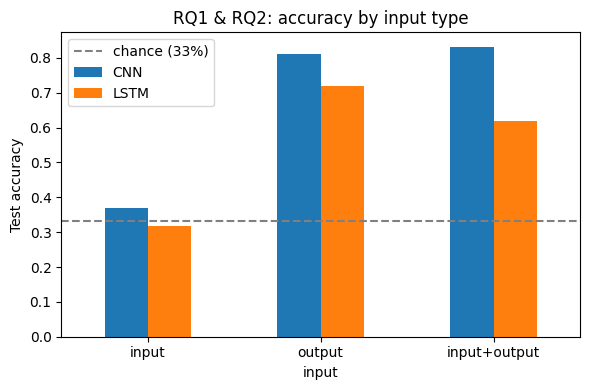

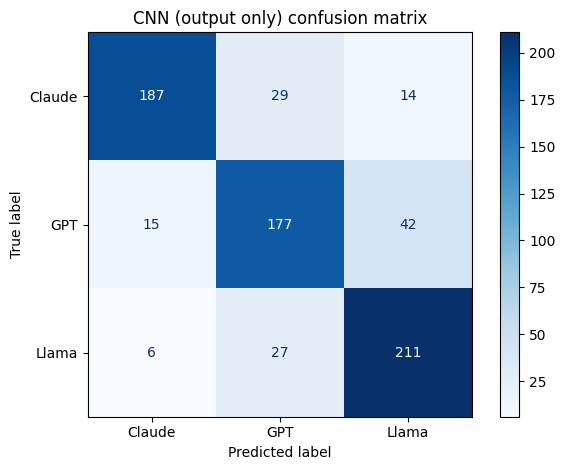

[[187  29  14]
 [ 15 177  42]
 [  6  27 211]]


In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

#Bar chart of all results
pivot = res.pivot(index="input", columns="model", values="test_acc").loc[["input", "output", "input+output"]]
ax = pivot.plot(kind="bar", rot=0, figsize=(6, 4))
ax.axhline(1/3, ls="--", c="gray", label="chance (33%)")
ax.set_ylabel("Test accuracy"); ax.set_title("RQ1 & RQ2: accuracy by input type"); ax.legend()
plt.tight_layout(); plt.savefig("results_bar.png", dpi=150); plt.show()

#Confusion matrix
cm = res[(res.model == "CNN") & (res.input == "output")]["cm"].iloc[0]
ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(cmap="Blues")
plt.title("CNN (output only) confusion matrix")
plt.tight_layout(); plt.savefig("cnn_confusion.png", dpi=150); plt.show()

print(cm)

In [7]:
import os
print(os.listdir())

['.config', 'results.csv', 'results_bar.png', 'cnn_confusion.png', 'dataset.csv', 'sample_data']
